# LLM-Assisted Close Reading

The ‘Aeolus’ Episode of James Joyce’s *Ulysses*

Jasper Harrington [ORCID profile for Jasper Harrington](https://orcid.org/0009-0009-7363-5705) (University of Melbourne)  
[Michael Falk](https://michaelfalk.io) [ORCID profile for Michael Falk](https://orcid.org/0000-0001-9261-8390) (University of Melbourne)

## Introduction

In [ ]:
knitr::opts_chunk$set(
  collapse = TRUE,
  comment = "#>"
)

In [ ]:
library(aeolusmicrotexts)

In this presentation, we report on our experiments performing LLM-assisted close reading of the ‘Aeolus’ episode of James Joyce’s *Ulysses*. The ‘Aeolus’ episode marks a crucial “hermeneutic shift” in the novel ([Lawrence 1980, 392](#ref-lawrence_aeolus_1980)). In prior episodes, the novel’s language is primarily transparent and referential, as Joyce tries to create the illusion of a stream of consciousness; in ‘Aelous’, new voices are introduced, in the form of newspaper headlines, which interrupt the stream of consciousness and render the language opaque. Who is speaking? Is there a consciousness behind the words? Where is the divide between nature and artifice, between art and life? This “hermeneutic shift” continues in later episodes of the novel, as the language becomes increasingly opaque and self-referential.

Our aims in this paper are twofold:

> **Aim 1:** To try to discover new angles of interpretation with the assistance of LLMs.
>
> **Aim 2:** To try and determine best practices for open, reproducible literary-critical resaerch using LLMs.

To pursue these aims, we choose to focus on “mediatization” in the episode ([Schneider 1989](#ref-schneider_mediatization_1989)). The episode takes place in a newspaper office, and the episode’s key linguistic feature is the intrusion of newspaper headlines that ironically label the action. We therefore analyse the language of the episode as media discourse, using a traditional text-analytic technique (lexicon-based sentiment analysis) and an LLM-assisted analogue of this technique (LLM-based sentiment and thematic analysis).

## Literature Review

Some references… Brockman et al. ([2018](#ref-brockman_publishing_2018))

## The Reproducible Pipeline

LLMs are powerful but flawed tools for text analysis. In our view, existing practices of open, reproducible scholarship are already sufficient to realise much of the power while mitigating the flaws.

LLMs are powerful primarily because of *in-context learning* and *structured outputs*. In-context learning is a powerful technique for controlling the LLM’s response to data: the researcher provides contextual clues in the prompt, enabling the LLM to respond more sensitively to the input data ([Ornstein et al. 2025, 269](#ref-ornstein_how_2025)) Structured outputs make the output easier to process, by ensuring that it conforms to a provided json schema ([“Structured Model Outputs OpenAI API,” n.d.](#ref-openai_structured_data_docs)). This does not prevent hallucinations, but does ensure that data is uniformly formatted for processing.

They are flawed because they are inherently *inexplicable* and *unreliable*. The problem of LLM explicability is well known ([Goebel et al. 2018](#ref-goebel_explainable_2018)). LLMs have billions or trillions of parameters that defy interpretation. Existing models have no power of introspection, meaning that they can never give genuine explanations of their own actions. The problem of LLM unreliability has only recent been subject to serious research ([Barke and Murali 2026](#ref-barke_agents_2026); [Rabanser et al. 2026](#ref-rabanser_towards_2026)). Early research is not promising: as LLMs have become more capable, they have not been getting more reliable. Even as LLMs have become more capable, their consistency, robustness, predictability, calibration and safety have hardly improved ([Rabanser et al. 2026](#ref-rabanser_towards_2026)).

To address these flaws, we adopt the following principles for our pipeline:

1.  Run the analysis locally: We use Ollama to run all LLM analysis locally, on NVidia A100 GPUS available on our University’s HPC cluster
2.  Set temperature to 0: When temperature is set to 0, LLMs become deterministic, always giving the same output to the same prompt.
3.  Systematically vary the prompt and data: Rather than interacting with the LLM in a chat environment to determine which prompt will work, we systematically run the analysis with different prompts and data structures, to assess what difference they make.
4.  Make the pipeline fully reproducible: When we run a set of experiments, full data are recorded for inspection by other scholars. All experimental data and LLM orchestration code are stored in a research compendium in the form of an installable R package.
5.  Evaluate LLM analysis against other approaches: Since the aim of our project is LLM-assisted close reading, we evaluate the LLM analysis against our own close reading of the text, supplemented with traditional, well-understood text analytic techniques (so far, lexicon-based sentiment analysis).

The data for the project is stored in a research compendium, which packages our experimental data with the code required to replicate it on an HPC cluster or sufficiently powerful local machine.

At the time of this abstract, one set of experimental data is available in the package (<a href="#tbl-list-runs" class="quarto-xref">Table 1</a>).

In [ ]:
list_runs() |> knitr::kable()

The results are stored in a long, self-describing format, to make their inspection and replication simpler for other scholars (<a href="#tbl-result-schema" class="quarto-xref">Table 2</a>).

In [ ]:
results <- read_run(run_id = "20261019-131523_v0.2.0.9000")

| column | meaning |
|------------------------------------|------------------------------------|
| `research_question` | Which research question is passed to the LLM: one of `"sentiment"` \| `"nationalism"` \| `"ugc"` |
| `model` | Name of the Ollama model that is passed to `ollama pull`, e.g. `"llama3.2:1b"` |
| `context_variant` | Which contextual clue is passed to the LLM: `"no_context"` (no information about where the text comes from), `"ulysses_context"` (LLM is told the text is from *Ulysses*), `"media_text_context"` (LLM is told that the text is social media text) |
| `granularity` | How ‘Aeolus’ is tokenised; it is either split into each `"microtext"`, or into each `"sentence"` |
| `include_headlines` | boolean; whether the headlines should be included in the corpus for analysis |
| `microtext` | Since the table has one row per unit, and each microtext could be split into multiple sentences, each row is labeled with the numeric id of each microtext. |
| `unit_index` | Since each microtext may be split into a sub-unit (the sentence), each row is labeled with a numeric index of the sub-unit (if `granuality == 'microtext'`), this is always `1`, since each microtext consists of 1 unit only. |
| `unit_of_analysis` | The exact text string sent to the LLM for this row’s classification call |
| `label` | The schema’s enum classification, e.g. `"positive"`, `"neutral"` and `"negative"` for the sentiment analysis schema. |
| `score` | The schema’s numeric score, always between -1 and 1 |

Table 2: Data schema for experimental results

As part of our research compendium, we provide a utility allowing researchers to see exactly how the LLM is prompted. Since we run the LLMs locally, we have full control over the exact prompt: it appears that cloud providers sometimes modify user prompts without warning.

In [ ]:
preview_prompt(
  schema = sentiment_schema,
  context_variant = "ulysses_context",
  unit = " DEAR DIRTY DUBLIN

Dubliners.

—Two Dublin vestals, Stephen said, elderly and pious, 
have lived fifty and fiftythree years in Fumbally’s lane. [...]"
)
#> ------------------------------------------------------------
#> SYSTEM PROMPT (fixed instructions for experiment)
#> ------------------------------------------------------------
#> This text is from James Joyce's novel Ulysses. Classify the
#> sentiment of this text as positive, neutral, or negative.
#> 
#> ## Output fields
#> 
#> Respond with a JSON object containing these fields, in this
#> order.
#> 
#> ### label
#> Overall sentiment of the text.
#> Allowed values: "positive", "neutral", "negative".
#> 
#> ### score
#> Sentiment intensity, from -1 (most negative) to 1 (most
#> positive).
#> Type: number.
#> ------------------------------------------------------------
#> USER TURN (datum for analysis)
#> ------------------------------------------------------------
#> ## The text
#> 
#>  DEAR DIRTY DUBLIN
#> 
#> Dubliners.
#> 
#> —Two Dublin vestals, Stephen said, elderly and pious,
#> have lived fifty and fiftythree years in Fumbally’s lane.
#> [...]
#> ------------------------------------------------------------
#> JSON SCHEMA (constrains output; not seen by model)
#> ------------------------------------------------------------
#> {
#>   "type": "object",
#>   "description": "Classify the sentiment of this text as
#>   positive, neutral, or negative",
#>   "properties": {
#>     "label": {
#>       "type": "string",
#>       "description": "Overall sentiment of the text",
#>       "enum": ["positive", "neutral", "negative"]
#>     },
#>     "score": {
#>       "type": "number",
#>       "description": "Sentiment intensity, from -1 (most
#>       negative) to 1 (most positive)"
#>     }
#>   },
#>   "required": ["label", "score"],
#>   "additionalProperties": false
#> }

## Early Results

In [ ]:
map_sentiments <- function(data, lexicon = c("bing", "afinn", "loughran", "syuzhet")) {
  # Assumes that `data` has a `word` column for matching
  lexicon <- rlang::arg_match(lexicon)
  sentiment_dictionary <- 
  if (lexicon == "syuzhet") {
    sentiment_dictionary <- syuzhet::get_sentiment_dictionary()
  } else {
    sentiment_dictionary <- tidytext::get_sentiments(lexicon)
  }
  # Add column
  data <- dplyr::left_join(
    data,
    sentiment_dictionary,
    by = dplyr::join_by(word)
  )
  # Remove numerical scores
  if ("value" %in% names(data)) {
    data <- dplyr::mutate(data, sentiment = dplyr::if_else(value > 0, "positive", "negative", NA))
    data <- dplyr::select(data, -value)
  }
  # Rename column
  lookup <- "sentiment"
  names(lookup) <- lexicon
  data <- dplyr::rename(data, dplyr::any_of(lookup))
  return(data)
}

classic_sentiment_analysis <- aeolusmicrotexts::load_aeolus(granularity = "microtext", include_headlines = TRUE) |> 
  tidytext::unnest_tokens(output = word, input = unit_of_analysis) |> 
  # Did not use loughran or nrc because they sort sentiments into too many categories
  map_sentiments("afinn") |> 
  map_sentiments("bing") |> 
  map_sentiments("syuzhet")

What is the expected maximum for sentimentally-laden words in each microtext? (Inspired by VADER)

In [ ]:
classic_sentiment_scores <- classic_sentiment_analysis |> 
  tidyr::pivot_longer(cols = c(afinn, bing, syuzhet), names_to = "lexicon", values_to = "score") |> 
  tidyr::drop_na() |> 
  dplyr::group_by(microtext, lexicon, score) |> 
  dplyr::tally() |> 
  dplyr::ungroup() |> 
  tidyr::pivot_wider(names_from = score, values_from = n, values_fill = 0) |> 
  dplyr::mutate(total = positive - negative)

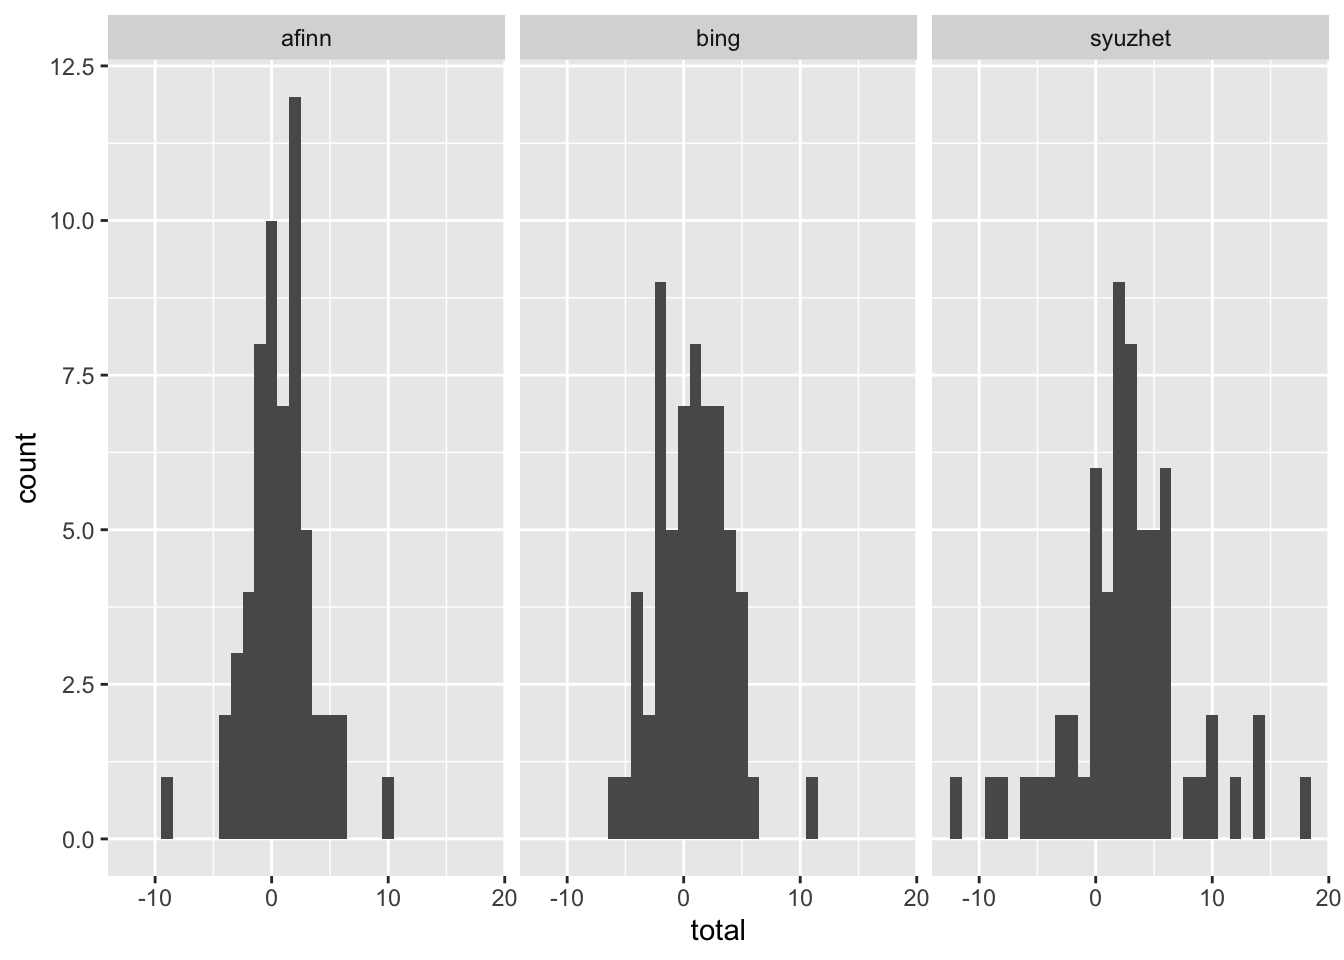

In [ ]:
classic_sentiment_scores |> 
  ggplot2::ggplot(ggplot2::aes(x = total)) + 
  ggplot2::geom_histogram(binwidth = 1) + 
  ggplot2::facet_wrap(ggplot2::vars(lexicon))

This confirms an expected maximum of 10. Thus we can normalise like so:

In [ ]:
classic_sentiment_scores <- classic_sentiment_scores |> 
  dplyr::mutate(compound = total / sqrt(total ^ 2 + 10)) |> 
  dplyr::mutate(consensus = all(compound > 0) | all(compound < 0), .by = microtext)

Now we have a compound score per microtext, bounded to -1 and 1 like the scores from the LLMs

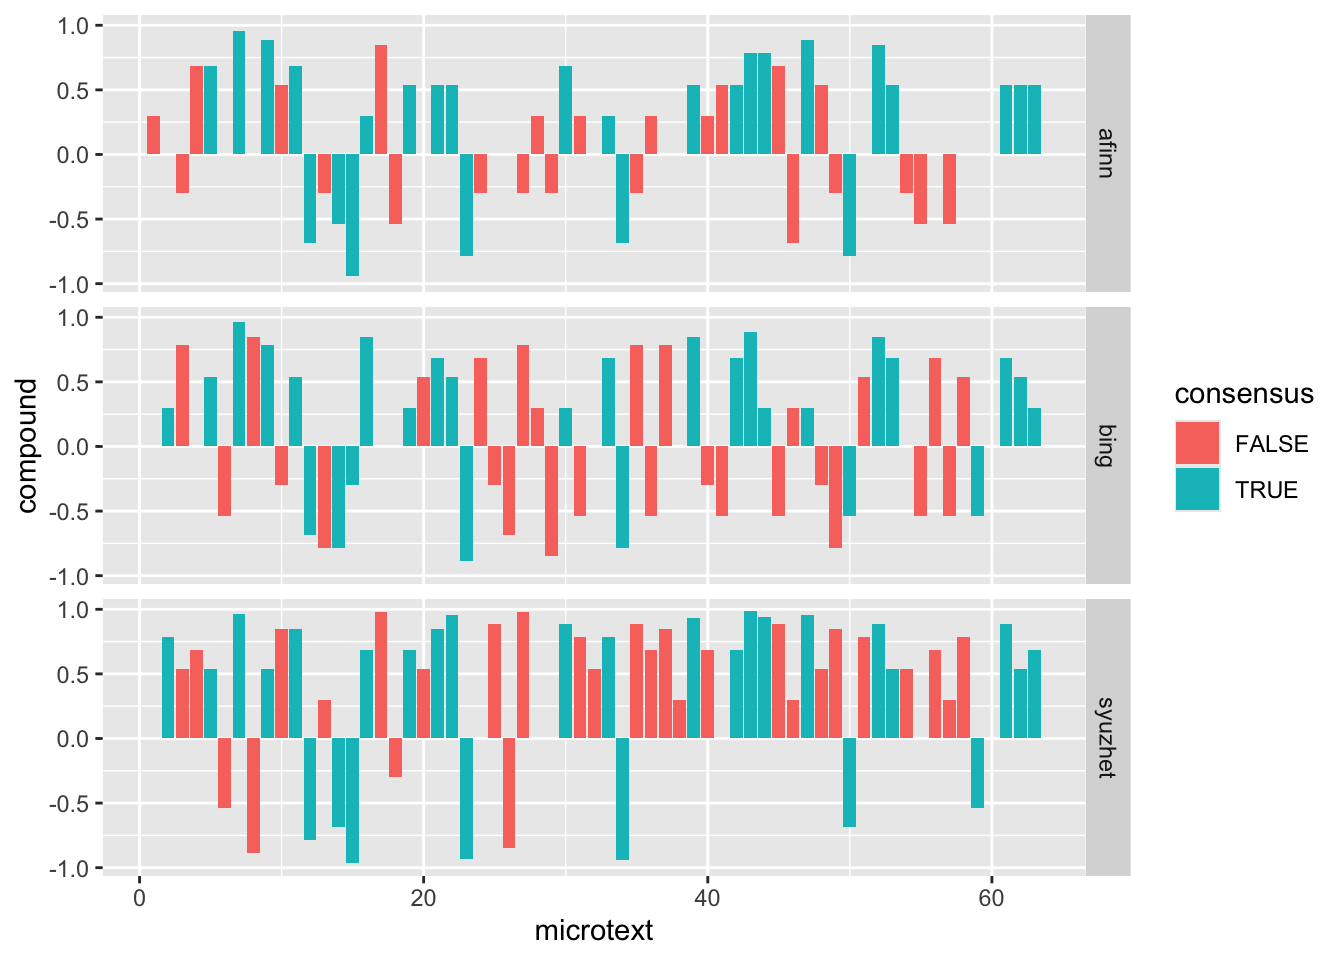

In [ ]:
classic_sentiment_scores |> 
  ggplot2::ggplot(ggplot2::aes(x = microtext, y = compound, fill = consensus)) +
  ggplot2::geom_col() + 
  ggplot2::facet_grid(rows = ggplot2::vars(lexicon))

What is the overall consensus?

In [ ]:
classic_sentiment_scores |> 
  dplyr::distinct(microtext, consensus) |> 
  dplyr::count(consensus) |> 
  dplyr::mutate(prop = n / sum(n))
#> # A tibble: 2 × 3
#>   consensus     n  prop
#>   <lgl>     <int> <dbl>
#> 1 FALSE        34 0.548
#> 2 TRUE         28 0.452

How do these classic scores compare to the LLM scores?

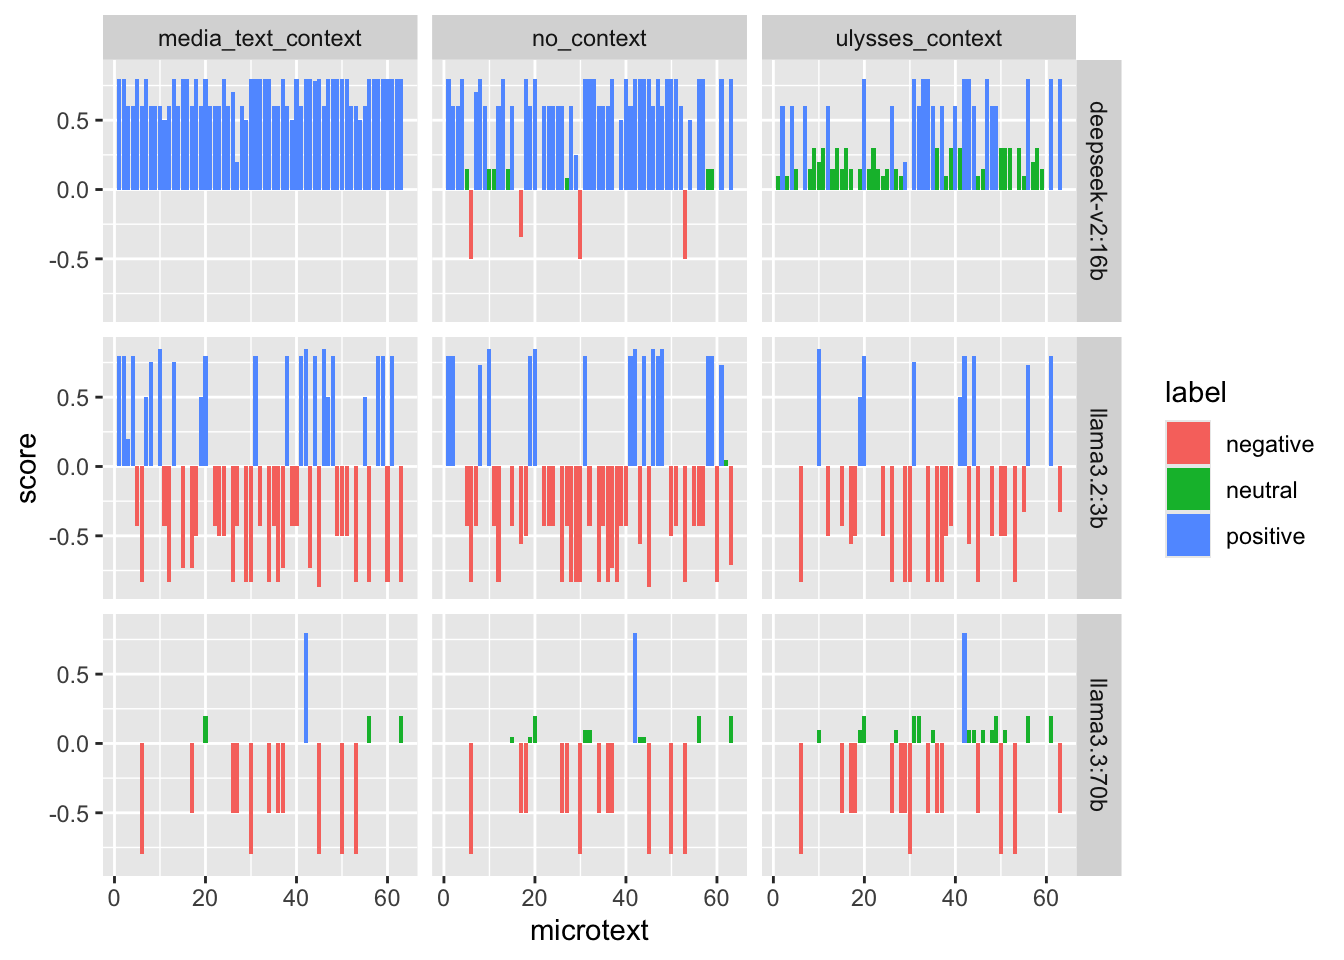

In [ ]:
results |> 
  dplyr::filter(granularity == "microtext", include_headlines == TRUE, research_question == "sentiment") |> 
  ggplot2::ggplot(ggplot2::aes(microtext, score, fill = label)) + 
  ggplot2::geom_col() + 
  ggplot2::facet_grid(rows = ggplot2::vars(model), cols = ggplot2::vars(context_variant))

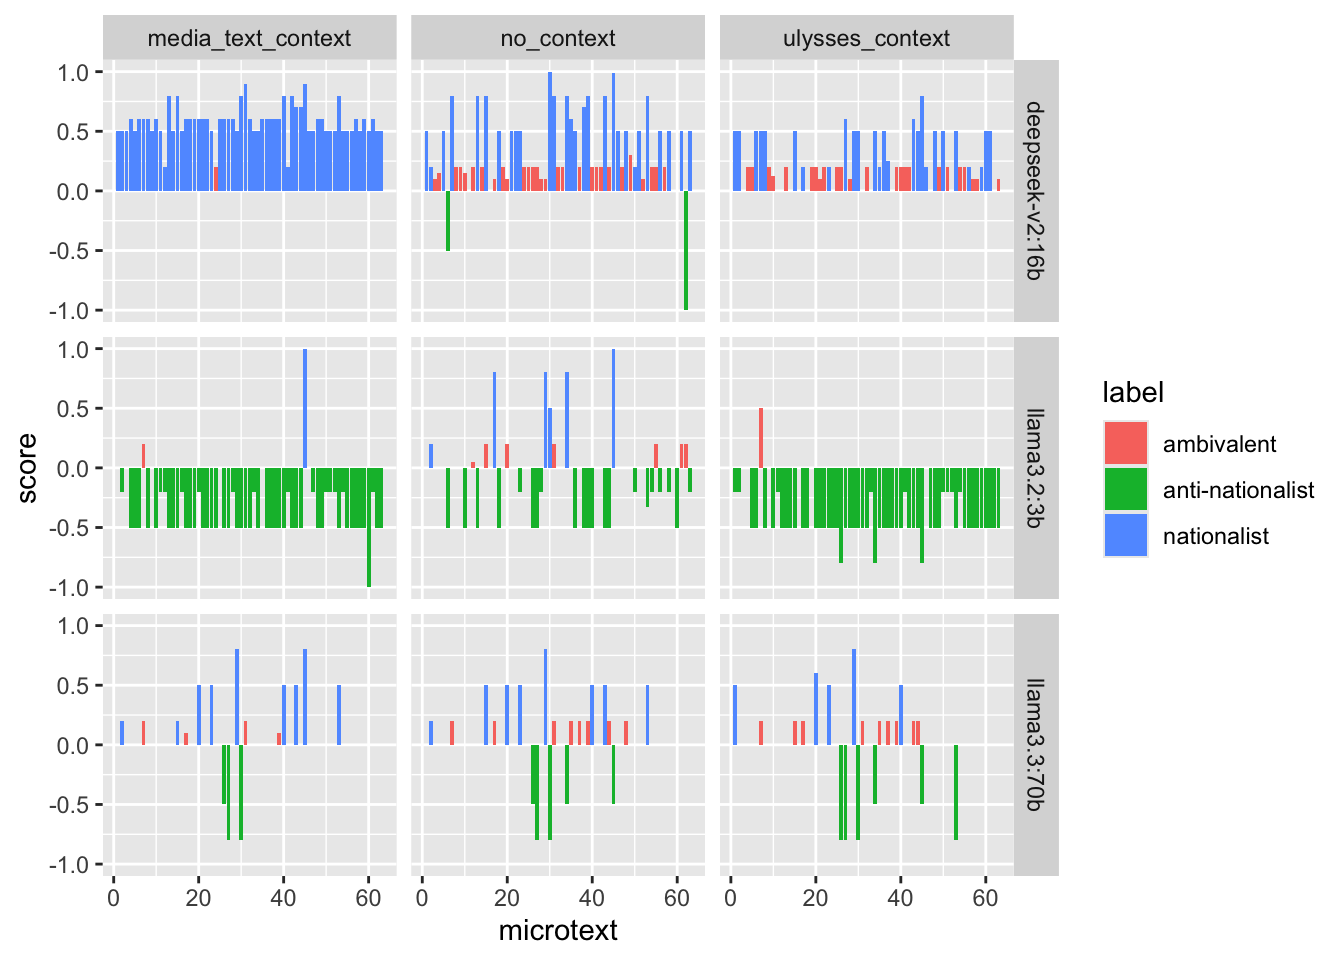

In [ ]:
results |> 
  dplyr::filter(granularity == "microtext", include_headlines == TRUE, research_question == "nationalism") |> 
  ggplot2::ggplot(ggplot2::aes(microtext, score, fill = label)) + 
  ggplot2::geom_col() + 
  ggplot2::facet_grid(rows = ggplot2::vars(model), cols = ggplot2::vars(context_variant))

In [ ]:
results |> 
  dplyr::filter(granularity == "microtext", include_headlines == TRUE, research_question == "nationalism") |> 
  dplyr::filter(model == "llama3.3:70b") |> 
  dplyr::arrange(dplyr::desc(score)) |> 
  dplyr::select(context_variant, microtext, label, score)
#> # A tibble: 189 × 4
#>    context_variant    microtext label       score
#>    <chr>                  <int> <chr>       <dbl>
#>  1 media_text_context        29 nationalist   0.8
#>  2 media_text_context        45 nationalist   0.8
#>  3 no_context                29 nationalist   0.8
#>  4 ulysses_context           29 nationalist   0.8
#>  5 ulysses_context           20 nationalist   0.6
#>  6 media_text_context        20 nationalist   0.5
#>  7 media_text_context        23 nationalist   0.5
#>  8 media_text_context        40 nationalist   0.5
#>  9 media_text_context        43 nationalist   0.5
#> 10 media_text_context        53 nationalist   0.5
#> # ℹ 179 more rows

## An Example: Microtext #43

## References

Barke, Shraddha, and Adithya Murali. 2026. “Agents as Software: A Programming Languages Agenda for Agent Reliability.” *Proceedings of the 2026 ACM SIGPLAN International Symposium on New Ideas, New Paradigms, and Reflections on Programming and Software* (New York, NY, USA), Onward! ’26, October, 179–90. <https://doi.org/10.1145/3840586.3843744>.

Brockman, William, Tekla Mecsnóber, and Sabrina Alonso. 2018. “Publishing in Joyce’s *Ulysses*: Newspapers, Advertising and Printing.” In *Publishing in Joyce’s *Ulysses**. Brill. <https://brill.com/display/title/36050>.

Goebel, Randy, Ajay Chander, Katharina Holzinger, et al. 2018. “Explainable AI: The New 42?” In *Machine Learning and Knowledge Extraction*, edited by Andreas Holzinger, Peter Kieseberg, A Min Tjoa, and Edgar Weippl. Lecture Notes in Computer Science. Springer International Publishing. <https://doi.org/10.1007/978-3-319-99740-7_21>.

Lawrence, Karen R. 1980. “"Aeolus": Interruption and Inventory.” *James Joyce Quarterly* 17 (4): 389–405. <https://www.jstor.org/stable/25476319>.

Ornstein, Joseph T., Elise N. Blasingame, and Jake S. Truscott. 2025. “How to Train Your Stochastic Parrot: Large Language Models for Political Texts.” *Political Science Research and Methods* 13 (2): 264–81. <https://doi.org/10.1017/psrm.2024.64>.

Rabanser, Stephan, Sayash Kapoor, Peter Kirgis, Kangheng Liu, Saiteja Utpala, and Arvind Narayanan. 2026. *Towards a Science of AI Agent Reliability*. arXiv. <https://doi.org/10.48550/arXiv.2602.16666>.

Schneider, Ulrich. 1989. “Mediatization in "Aeolus" and "Oxen of the Sun".” *European Joyce Studies* 1: 15–21. <https://www.jstor.org/stable/44871172>.

“Structured Model Outputs OpenAI API.” n.d. In *OpenAI Developers*. Accessed November 11, 2026. <https://developers.openai.com/api/docs/guides/structured-outputs>.